# Phase 2 — Cheap Uncertainty Estimation for GPM
Can one or two K=16 predictions identify nodes that benefit from K=128? We reuse the frozen Amazon Computers GPM and Phase 1 predictions. No training, adaptive inference, stopping rules, or new sampling strategies are introduced.

**Exploratory analysis:** these test nodes have already been examined. No validation-node prediction cache was found. Results support a provisional choice for future validation, not an untouched test evaluation.

Run requirements: Python with NumPy, pandas, SciPy, scikit-learn, matplotlib, IPython, and Modal; authenticated access to the original Modal profile is required for the timing cell. Run from the project folder; data paths are explicit. The executed outputs below include the measured timings, so reading this notebook requires no GPU access.

In [1]:
from pathlib import Path
import os
import sys
import json
import hashlib
import time
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
from IPython.display import display, Markdown

ROOT = Path('/Users/arvind/Documents/research/experiments/uncertainty-estimation-gpm')
CACHE = ROOT / 'sampling_experiment_results/computers_sampling_full.npz'
RESULTS = ROOT / 'sampling_benefit_diagnostic/results'
SEED = 20261030
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (8, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
assert CACHE.is_file()
print('Python:', platform.python_version(), '| NumPy:', np.__version__)
print('Cache SHA256:', hashlib.sha256(CACHE.read_bytes()).hexdigest())

Python: 3.11.16 | NumPy: 2.4.6
Cache SHA256: db45b031ffcb04e26e06964f2e94242483fdb437481114e6b712578bb692be2b


## Existing model, data, and sampling provenance
Inspected `experiments.ipynb`, `sampling_benefit_walkthrough.ipynb`, `sampling_benefit_diagnostic/experiment.py`, and `GPM/GPM/sampling_experiment.py`. The cache holds 50 runs for each K in {4,8,16,32,64,128}, including labels and ordered node IDs. Its checkpoint is `/workspace/GPM/model/computers/epoch_380.pt`, verified in Modal volume `gpm-models` (profile `arvindajaybharadwaj23`). Amazon Computers data is in `gpm-data/Computers`.

The original loader uses seed 42, the first `high` split (60/20/20), normalized features, undirected edges, and 8-dimensional Laplacian positional encodings. Local raw data, checkpoint, and saved split masks are absent. The timing cell below loads the original implementation remotely, freezes the checkpoint, and checks reconstructed test IDs and labels against the cache. No model code is copied or modified.

In [2]:
with np.load(CACHE, allow_pickle=False) as saved:
    probabilities = saved['probabilities'].astype(np.float64)
    labels = saved['labels'].astype(int)
    node_ids = saved['node_ids'].astype(int)
    k_values = saved['k_values'].astype(int)
    checkpoint_path = str(saved['checkpoint'].item())
    assert int(saved['repeats']) == probabilities.shape[1] == 50
    assert int(saved['completed_k_index']) == len(k_values) - 1

assert probabilities.shape == (len(k_values), 50, len(node_ids), 10)
assert len(labels) == len(node_ids) == len(np.unique(node_ids))
assert labels.min() >= 0 and labels.max() < 10
assert np.isfinite(probabilities).all()
assert ((probabilities >= 0) & (probabilities <= 1)).all()
np.testing.assert_allclose(probabilities.sum(-1), 1, atol=1e-6, rtol=0)
k_index = {int(k): i for i, k in enumerate(k_values)}
assert {16, 128}.issubset(k_index)
print('Shape [K, run, node, class]:', probabilities.shape)
print('Recorded checkpoint:', checkpoint_path)

Shape [K, run, node, class]: (6, 50, 2751, 10)
Recorded checkpoint: /workspace/GPM/model/computers/epoch_380.pt


## Benefit and independent uncertainty samples
Preserve the earlier diagnostic's split: uncertainty uses runs **0–24**; benefit uses **25–49** at both endpoints. The cheap measures use only runs 0 and 1, with no overlap with benefit. Using all 50 runs for benefit would leak samples into the 25-pass reference, so we deliberately use the same 25 held-out runs for every method.

The original sampling script specifies seed `10000 + 1000*K + run` (therefore 26000 and 26001 for the cheap estimates). The actual seeds were not recorded in the NPZ; independence is supported by the inspected generation code and disjoint run indices, not independently verifiable RNG metadata. Benefit is a noisy repeated-sampling estimate, not an intrinsic node property. No labels enter the uncertainty scores.

In [3]:
uncertainty_runs = np.arange(25)
benefit_runs = np.arange(25, 50)
assert not np.intersect1d(uncertainty_runs, benefit_runs).size
p16_uncertainty = probabilities[k_index[16], uncertainty_runs]
accuracy16 = (probabilities[k_index[16], benefit_runs].argmax(-1) == labels).mean(0)
accuracy128 = (probabilities[k_index[128], benefit_runs].argmax(-1) == labels).mean(0)
benefit = accuracy128 - accuracy16
error16, error128 = 1 - accuracy16, 1 - accuracy128
np.testing.assert_allclose(benefit, error16 - error128)
print(f'{len(node_ids):,} previously inspected test nodes; 25 benefit runs per K.')
print(f'Overall accuracy: {100*accuracy16.mean():.3f}% → {100*accuracy128.mean():.3f}%')
print(f'Overall benefit: {100*benefit.mean():.3f} percentage points')
print('Positive / zero / negative benefit:',
      [int((benefit > 0).sum()), int((benefit == 0).sum()), int((benefit < 0).sum())])

2,751 previously inspected test nodes; 25 benefit runs per K.
Overall accuracy: 89.714% → 90.907%
Overall benefit: 1.192 percentage points
Positive / zero / negative benefit: [365, 2270, 116]


## Three cheap scores and the saved reference
Confidence and entropy share exactly the same first probability vector. Total variation uses that vector and one additional independent run. Reusing cached forward outputs avoids rerunning inference for these scores.

The previous 25-pass estimator in the walkthrough is **the trace of the sample covariance of probabilities**, not entropy of their mean. Load its saved per-node scores and verify their definition and alignment. The older `experiments.ipynb` also explored an entropy-gap score over 50 runs; that is not the 25-pass reference used here.

In [4]:
p1, p2 = p16_uncertainty[0], p16_uncertainty[1]
scores = {
    'Maximum confidence': 1 - p1.max(-1),
    'Predictive entropy': -(p1 * np.log(np.clip(p1, 1e-12, 1))).sum(-1),
    'Sampling disagreement': 0.5 * np.abs(p1 - p2).sum(-1),
}
cheap_methods = list(scores)
previous_file = RESULTS / 'per_node.csv'
if previous_file.is_file():
    previous = pd.read_csv(previous_file).set_index('node_id').loc[node_ids]
    np.testing.assert_array_equal(previous['label'], labels)
    assert (previous['checkpoint'] == checkpoint_path).all()
    assert (previous['split'] == 'test').all()
    previous_config = json.loads((RESULTS / 'config.json').read_text())
    assert previous_config['group_A'] == uncertainty_runs.tolist()
    assert previous_config['group_B'] == benefit_runs.tolist()
    assert previous_config['input_sha256'] == hashlib.sha256(CACHE.read_bytes()).hexdigest()
    reference_score = previous['sampling_variance'].to_numpy()
    np.testing.assert_allclose(reference_score, p16_uncertainty.var(0, ddof=1).sum(-1), atol=1e-14)
    np.testing.assert_allclose(previous['delta_error'], benefit, atol=1e-14)
    scores['Previous estimator'] = reference_score
    print('Loaded and verified saved 25-pass sampling variance. No reference inference rerun.')
else:
    print('Previous scores unavailable; reference metrics will be unavailable.')
for name, score in scores.items():
    assert score.shape == benefit.shape and np.isfinite(score).all()

Loaded and verified saved 25-pass sampling variance. No reference inference rerun.


## Measured computation cost
The following small timing experiment imports the existing GPM and sampler in their original Modal environment. It performs one warm-up batch, then two full K=16 evaluation sweeps (256-node batches), using fresh fixed seeds. Timing includes seeding, fresh pattern sampling, model execution, softmax, CPU transfer, and score calculation, with CUDA synchronization. Data/model loading, startup, and the warm-up are excluded. The frozen checkpoint and node alignment are verified before timing.

A “pass” in Table 1 means one sweep over all evaluation nodes; each sweep contains 11 actual batched model calls. Confidence and entropy share the first sweep; disagreement needs both. Times are one observed measurement, not a latency benchmark with repeated trials. The 25-pass reference has no saved latency and is **not** rerun or assigned an extrapolated time.

In [5]:
# This code runs inside the existing GPM environment; all new experiment code stays here.
remote_timing_code = r"""
import sys, json, time, hashlib, copy
import numpy as np
import torch
sys.path.insert(0, '/workspace/GPM/GPM')
from sampling_experiment import load_baseline_params, set_sampling_seed
from data.pyg_data_loader import load_data
from model.model import Model
from model.random_walk import get_patterns
from utils.utils import seed_everything, mask2idx

seed_everything(42)
params = load_baseline_params('computers')
params['device'] = torch.device('cuda:0')
graph, splits = load_data(params)
params['input_dim'] = graph.x.size(1)
params['edge_dim'] = graph.edge_attr.size(1) if graph.edge_attr is not None else 0
params['output_dim'] = int(graph.y.max()) + 1
checkpoint = '/workspace/GPM/model/computers/epoch_380.pt'
model = Model(params=params).to(params['device'])
model.load_state_dict(torch.load(checkpoint, map_location=params['device']))
model.eval()
for parameter in model.parameters():
    parameter.requires_grad_(False)
nodes = mask2idx(splits[0]['test'])
assert nodes.cpu().tolist() == EXPECTED_IDS
assert graph.y[nodes].cpu().tolist() == EXPECTED_LABELS
assert not model.training and not any(p.requires_grad for p in model.parameters())

@torch.no_grad()
def predict_batch(batch_nodes):
    run_params = copy.copy(params)
    run_params['pre_sample_pattern_num'] = 16
    patterns, eids = get_patterns(graph, run_params, nodes=batch_nodes)
    run_params['pattern_set'] = {'pattern': patterns, 'eid': eids}
    local_nodes = torch.arange(len(batch_nodes), dtype=torch.long)
    logits, _, _, _ = model(graph, local_nodes, run_params, mode='eval')
    return logits.softmax(-1).cpu().numpy().astype(np.float64)

set_sampling_seed(20261029)
predict_batch(nodes[:256])  # Warm-up is excluded.
torch.cuda.synchronize()
pass_seconds, outputs = [], []
for seed in [20261030, 20261031]:
    torch.cuda.synchronize()
    start = time.perf_counter()
    set_sampling_seed(seed)
    outputs.append(np.concatenate([predict_batch(nodes[i:i+256]) for i in range(0, len(nodes), 256)]))
    torch.cuda.synchronize()
    pass_seconds.append(time.perf_counter() - start)
first, second = outputs
start = time.perf_counter()
confidence = 1 - first.max(-1)
confidence_seconds = time.perf_counter() - start
start = time.perf_counter()
entropy = -(first * np.log(np.clip(first, 1e-12, 1))).sum(-1)
entropy_seconds = time.perf_counter() - start
start = time.perf_counter()
disagreement = 0.5 * np.abs(first-second).sum(-1)
disagreement_seconds = time.perf_counter() - start
result = dict(gpu=torch.cuda.get_device_name(), nodes=len(nodes), batch_size=256,
    batches_per_sweep=int(np.ceil(len(nodes)/256)), pass_seconds=pass_seconds,
    confidence_seconds=confidence_seconds, entropy_seconds=entropy_seconds,
    disagreement_seconds=disagreement_seconds, split_ids_and_labels_verified=True,
    checkpoint_sha256=hashlib.sha256(open(checkpoint, 'rb').read()).hexdigest())
print('PHASE2_TIMING=' + json.dumps(result))
"""
remote_timing_code = ('EXPECTED_IDS = ' + repr(node_ids.tolist()) + '\n' +
                      'EXPECTED_LABELS = ' + repr(labels.tolist()) + '\n' + remote_timing_code)

In [6]:
import modal
import importlib

# Use the account where the existing model and data were verified.
os.environ['MODAL_PROFILE'] = 'arvindajaybharadwaj23'
sys.path.insert(0, str(ROOT / 'GPM'))
old_directory = Path.cwd()
try:
    os.chdir(ROOT / 'GPM')
    original_environment = importlib.import_module('modal_gpm')
    timing_app = modal.App('gpm-phase2-timing')
    volumes = {
        '/workspace/GPM/data': modal.Volume.from_name('gpm-data', create_if_missing=False),
        '/workspace/GPM/model': modal.Volume.from_name('gpm-models', create_if_missing=False),
    }
    with timing_app.run():
        sandbox = modal.Sandbox.create(
            original_environment.GPM_PYTHON, '-c', remote_timing_code,
            app=timing_app, image=original_environment.image, gpu='L40S',
            volumes=volumes, workdir='/workspace/GPM', timeout=1800)
        try:
            remote_stdout = sandbox.stdout.read()
            remote_stderr = sandbox.stderr.read()
            sandbox.wait()
            if sandbox.returncode != 0:
                raise RuntimeError(remote_stderr[-6000:] + remote_stdout[-3000:])
        finally:
            sandbox.terminate()
    timing_line = next(line for line in remote_stdout.splitlines() if line.startswith('PHASE2_TIMING='))
    timing = json.loads(timing_line.split('=', 1)[1])
finally:
    os.chdir(old_directory)
print(json.dumps(timing, indent=2))
first_seconds, second_seconds = timing['pass_seconds']
method_seconds = {
    'Maximum confidence': first_seconds + timing['confidence_seconds'],
    'Predictive entropy': first_seconds + timing['entropy_seconds'],
    'Sampling disagreement': first_seconds + second_seconds + timing['disagreement_seconds'],
}

{
  "gpu": "NVIDIA L40S",
  "nodes": 2751,
  "batch_size": 256,
  "batches_per_sweep": 11,
  "pass_seconds": [
    0.0807632930000004,
    0.08342532200000008
  ],
  "confidence_seconds": 0.0001839839999995263,
  "entropy_seconds": 0.00026530600000285176,
  "disagreement_seconds": 9.498200000024326e-05,
  "split_ids_and_labels_verified": true,
  "checkpoint_sha256": "1c2be9b7bf672074040a716caad220f514e490c8dbf4700cafc7d3db61371877"
}


## Table 1: Cheap Uncertainty Comparison
Rank correlations use all nodes. Positive measured benefit is the AUROC target; AUROC is unavailable when only one target class exists. Select exactly `floor(0.20 × N)` nodes, breaking uncertainty ties by ascending node ID. No rounding is applied before constructing the benefit target.

Pattern counts are per node, with totals across all nodes shown alongside them. Shared confidence/entropy inference is not additive. “Time” is the measured full-sweep estimation time and its per-node amortization; the two cheap cached runs used for statistical metrics are not rerun.

In [7]:
passes = dict(zip(cheap_methods, [1, 1, 2]))
passes['Previous estimator'] = 25
number_selected = int(np.floor(0.20 * len(node_ids)))
assert number_selected > 0
selected_nodes = {}
rows = []
for name in cheap_methods + ['Previous estimator']:
    score = scores.get(name)
    rho = top_benefit = auroc = np.nan
    if score is not None:
        selected = np.lexsort((node_ids, -score))[:number_selected]
        selected_nodes[name] = selected
        if np.ptp(score) > 0 and np.ptp(benefit) > 0:
            rho = float(spearmanr(score, benefit).statistic)
        top_benefit = 100 * benefit[selected].mean()
        if len(np.unique(benefit > 0)) == 2:
            auroc = roc_auc_score(benefit > 0, score)
    seconds = method_seconds.get(name)
    time_text = ('Unavailable (not saved)' if seconds is None else
                 f'{seconds:.3f} s/sweep; {1000*seconds/len(node_ids):.3f} ms/node')
    patterns = 16 * passes[name]
    rows.append({'Method': name, 'Passes': passes[name],
                 'Patterns/node (total)': f'{patterns} ({patterns*len(node_ids):,})',
                 'Spearman': rho, 'Top 20% Benefit (pp)': top_benefit,
                 'AUROC': auroc, 'Time': time_text})
comparison = pd.DataFrame(rows).set_index('Method')
display(comparison.style.format({'Spearman': '{:.4f}', 'Top 20% Benefit (pp)': '{:.3f}',
                                 'AUROC': '{:.4f}'}, na_rep='Unavailable'))
print(f'Top 20%: {number_selected} / {len(node_ids)} nodes ({100*number_selected/len(node_ids):.3f}%).')
print(f'Batched model calls per sweep: {timing["batches_per_sweep"]}; one warm-up batch excluded.')

,Passes,Patterns/node (total),Spearman,Top 20% Benefit (pp),AUROC,Time
Method,,,,,,
Maximum confidence,1,"16 (44,016)",0.2562,4.640,0.8695,0.081 s/sweep; 0.029 ms/node
Predictive entropy,1,"16 (44,016)",0.2542,4.509,0.8654,0.081 s/sweep; 0.029 ms/node
Sampling disagreement,2,"32 (88,032)",0.2715,4.182,0.8872,0.164 s/sweep; 0.060 ms/node
Previous estimator,25,"400 (1,100,400)",0.3154,5.571,0.9468,Unavailable (not saved)


Top 20%: 550 / 2751 nodes (19.993%).
Batched model calls per sweep: 11; one warm-up batch excluded.


## Plot 1: Uncertainty versus benefit
Five groups contain equal numbers of nodes up to a one-node difference. Node ID breaks ties. A rising line suggests higher uncertainty identifies larger measured benefit.

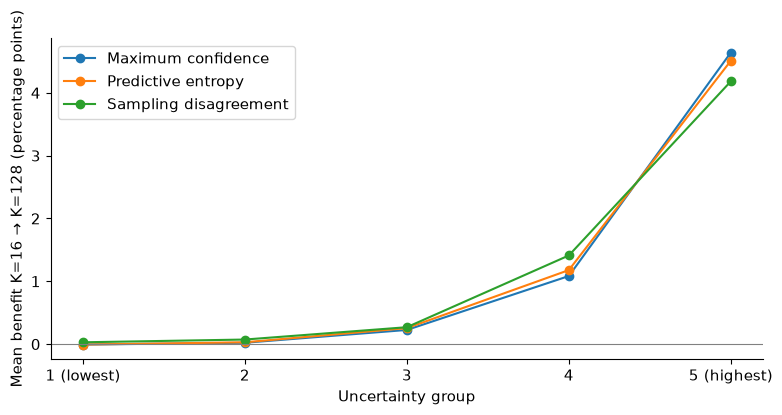

In [8]:
fig, ax = plt.subplots()
for name in cheap_methods:
    order = np.lexsort((node_ids, scores[name]))
    groups = np.array_split(order, 5)
    group_benefits = [100 * benefit[group].mean() for group in groups]
    ax.plot(range(1, 6), group_benefits, marker='o', label=name)
ax.axhline(0, color='grey', linewidth=0.8)
ax.set_xticks(range(1, 6), ['1 (lowest)', '2', '3', '4', '5 (highest)'])
ax.set(xlabel='Uncertainty group', ylabel='Mean benefit K=16 → K=128 (percentage points)')
ax.legend()
fig.tight_layout()
plt.show()

## Does uncertainty predict benefit or just errors?
Both errors below are fractions of the same held-out benefit runs. Improvement equals error at K=16 minus error at K=128, in percentage points. High error alone does not establish that additional sampling helps; compare improvement with the overall row.

In [9]:
error_rows = [{'Group': 'All nodes', 'Nodes': len(node_ids),
               'Error K=16 (%)': 100*error16.mean(), 'Error K=128 (%)': 100*error128.mean(),
               'Improvement (pp)': 100*benefit.mean()}]
for name, selected in selected_nodes.items():
    error_rows.append({'Group': name + ' — top 20%', 'Nodes': len(selected),
                       'Error K=16 (%)': 100*error16[selected].mean(),
                       'Error K=128 (%)': 100*error128[selected].mean(),
                       'Improvement (pp)': 100*benefit[selected].mean()})
error_check = pd.DataFrame(error_rows).set_index('Group')
display(error_check.round(3))

,Nodes,Error K=16 (%),Error K=128 (%),Improvement (pp)
Group,,,,
All nodes,2751,10.286,9.093,1.192
Maximum confidence — top 20%,550,32.735,28.095,4.640
Predictive entropy — top 20%,550,32.458,27.949,4.509
Sampling disagreement — top 20%,550,25.993,21.811,4.182
Previous estimator — top 20%,550,31.593,26.022,5.571


## Interpretation
The following conclusion is generated from the measured tables. A recommendation remains provisional: one fixed pair of cheap samples, a finite 25-run benefit estimate, one checkpoint, and previously examined test nodes do not establish generalization. Nominal pattern savings are known; a 25-pass latency speedup cannot be measured from missing historical timing.

In [10]:
cheap_table = comparison.loc[cheap_methods]
best_rho = cheap_table['Spearman'].idxmax()
best_top = cheap_table['Top 20% Benefit (pp)'].idxmax()
one_pass = cheap_table.loc[cheap_methods[:2]]
# Selection uses enrichment of benefit first; correlation is reported separately.
best_single = one_pass['Top 20% Benefit (pp)'].idxmax()
disagreement = comparison.loc['Sampling disagreement']
single = comparison.loc[best_single]
extra_gain = disagreement['Top 20% Benefit (pp)'] - single['Top 20% Benefit (pp)']
extra_rho = disagreement['Spearman'] - single['Spearman']
extra_auc = disagreement['AUROC'] - single['AUROC']
recommendation = best_single
if extra_gain > 0 and extra_rho > 0 and extra_auc > 0:
    cost_comment = ('Disagreement improves all three descriptive metrics, but these results do not establish '
                    'that its extra pass is worthwhile; retain the one-pass option pending validation.')
else:
    cost_comment = ('Disagreement does not improve all three descriptive metrics over the strongest '
                    'one-pass choice; its extra pass is not supported by this comparison.')
reference_comment = 'The previous 25-pass scores are unavailable, so their statistical gap cannot be measured.'
if 'Previous estimator' in scores:
    reference = comparison.loc['Previous estimator']
    chosen = comparison.loc[recommendation]
    reference_comment = (
        f'For {recommendation}, cheap minus previous is '
        f'{chosen["Spearman"]-reference["Spearman"]:+.4f} Spearman, '
        f'{chosen["Top 20% Benefit (pp)"]-reference["Top 20% Benefit (pp)"]:+.3f} pp top-group benefit, '
        f'and {chosen["AUROC"]-reference["AUROC"]:+.4f} AUROC. '
        'Negative differences mean worse performance. It requires 16 rather than 400 patterns/node '
        '(25× fewer); previous latency is unavailable.')
selected = selected_nodes[recommendation]
selected_gain = 100*benefit[selected].mean()
overall_gain = 100*benefit.mean()
benefit_comment = ('This is evidence of enrichment for reducible errors, as well as difficulty.'
                   if selected_gain > overall_gain and selected_gain > 0 else
                   'This does not show benefit enrichment beyond the overall node population.')
display(Markdown(f"""
- **Best cheap predictor:** {best_rho} has the highest Spearman ({cheap_table.loc[best_rho, 'Spearman']:.4f}); {best_top} has the largest top-20% benefit ({cheap_table.loc[best_top, 'Top 20% Benefit (pp)']:.3f} pp). These criteria need not agree.
- **Against 25 passes:** {reference_comment}
- **Second pass:** disagreement changes top-group benefit by {extra_gain:+.3f} pp, Spearman by {extra_rho:+.4f}, and AUROC by {extra_auc:+.4f} versus {best_single}. Its measured cost is {method_seconds['Sampling disagreement']/method_seconds[best_single]:.2f}× the one-pass time. {cost_comment}
- **Benefit versus difficulty:** {recommendation}'s selected nodes have error {100*error16[selected].mean():.3f}% → {100*error128[selected].mean():.3f}%, improving {selected_gain:.3f} pp versus {overall_gain:.3f} pp overall. {benefit_comment} Remaining error shows that uncertainty also includes difficulty that more patterns do not fix.
- **Provisional Phase 3 candidate:** {recommendation}, using one forward pass, because it has the larger top-group improvement among the one-pass options at essentially shared inference cost. This is a cost-conscious candidate to validate, not a confirmed winner. **Phase 3 is not implemented.**
"""))


- **Best cheap predictor:** Sampling disagreement has the highest Spearman (0.2715); Maximum confidence has the largest top-20% benefit (4.640 pp). These criteria need not agree.
- **Against 25 passes:** For Maximum confidence, cheap minus previous is -0.0592 Spearman, -0.931 pp top-group benefit, and -0.0773 AUROC. Negative differences mean worse performance. It requires 16 rather than 400 patterns/node (25× fewer); previous latency is unavailable.
- **Second pass:** disagreement changes top-group benefit by -0.458 pp, Spearman by +0.0154, and AUROC by +0.0177 versus Maximum confidence. Its measured cost is 2.03× the one-pass time. Disagreement does not improve all three descriptive metrics over the strongest one-pass choice; its extra pass is not supported by this comparison.
- **Benefit versus difficulty:** Maximum confidence's selected nodes have error 32.735% → 28.095%, improving 4.640 pp versus 1.192 pp overall. This is evidence of enrichment for reducible errors, as well as difficulty. Remaining error shows that uncertainty also includes difficulty that more patterns do not fix.
- **Provisional Phase 3 candidate:** Maximum confidence, using one forward pass, because it has the larger top-group improvement among the one-pass options at essentially shared inference cost. This is a cost-conscious candidate to validate, not a confirmed winner. **Phase 3 is not implemented.**
